In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Generate realistic data for Indian districts
np.random.seed(42)
n_districts = 150

# Three natural groups (e.g., Metro Hubs, Tier-2 Developing, Remote/Lagging)
group1_lit = np.random.normal(85, 5, 60)
group1_srv = np.random.normal(90, 6, 60)

group2_lit = np.random.normal(65, 6, 50)
group2_srv = np.random.normal(55, 7, 50)

group3_lit = np.random.normal(45, 5, 40)
group3_srv = np.random.normal(30, 5, 40)

literacy_rate = np.concatenate([group1_lit, group2_lit, group3_lit])
service_usage = np.concatenate([group1_srv, group2_srv, group3_srv])

df_districts = pd.DataFrame({
    'District_Name': [f"District_{i+1}" for i in range(n_districts)],
    'Digital_Literacy_Pct': np.clip(literacy_rate, 20, 100).round(1),
    'E_Governance_Usage_Pct': np.clip(service_usage, 10, 100).round(1)
})

In [2]:
df_districts.head()

,District_Name,Digital_Literacy_Pct,E_Governance_Usage_Pct
0,District_1,87.5,87.1
1,District_2,84.3,88.9
2,District_3,88.2,83.4
3,District_4,92.6,82.8
4,District_5,83.8,94.9


In [3]:
df_districts.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 3 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   District_Name           150 non-null    object 
 1   Digital_Literacy_Pct    150 non-null    float64
 2   E_Governance_Usage_Pct  150 non-null    float64
dtypes: float64(2), object(1)
memory usage: 3.6+ KB


In [4]:
df_districts.describe()

,Digital_Literacy_Pct,E_Governance_Usage_Pct
count,150.000000,150.000000
mean,67.489333,62.530667
std,16.595488,25.331266
min,34.900000,13.800000
25%,55.450000,37.975000
50%,68.300000,58.750000
75%,82.700000,88.675000
max,94.300000,100.000000


In [5]:
df_districts.tail()

,District_Name,Digital_Literacy_Pct,E_Governance_Usage_Pct
145,District_146,42.6,26.5
146,District_147,51.3,34.5
147,District_148,41.5,31.5
148,District_149,47.2,34.1
149,District_150,48.9,33.1


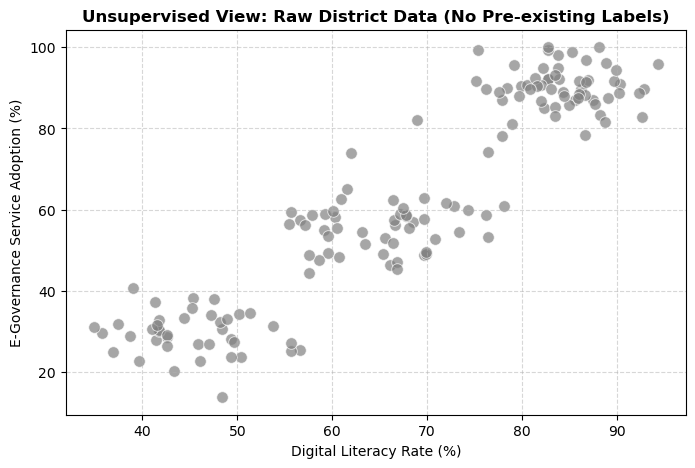

In [9]:
# 2. Plot the UNLABELLED data (What Unsupervised Learning sees first)
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df_districts, 
    x='Digital_Literacy_Pct', 
    y='E_Governance_Usage_Pct', 
    color='gray', 
    alpha=0.7, 
    s=70
)
plt.title("Unsupervised View: Raw District Data (No Pre-existing Labels)", fontsize=12, fontweight='bold')
plt.xlabel("Digital Literacy Rate (%)")
plt.ylabel("E-Governance Service Adoption (%)")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [14]:
from sklearn.cluster import KMeans

# 1. Select the features for clustering
X = df_districts[['Digital_Literacy_Pct', 'E_Governance_Usage_Pct']]

# 2. Apply K-Means to find K = 3 distinct clusters
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

# 3. Assign cluster labels to the dataframe
df_districts['Cluster_ID'] = kmeans.fit_predict(X)

# 4. Display the updated dataframe
df_districts

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


,District_Name,Digital_Literacy_Pct,E_Governance_Usage_Pct,Cluster_ID
0,District_1,87.5,87.1,0
1,District_2,84.3,88.9,0
2,District_3,88.2,83.4,0
3,District_4,92.6,82.8,0
4,District_5,83.8,94.9,0
...,...,...,...,...
145,District_146,42.6,26.5,1
146,District_147,51.3,34.5,1
147,District_148,41.5,31.5,1
148,District_149,47.2,34.1,1


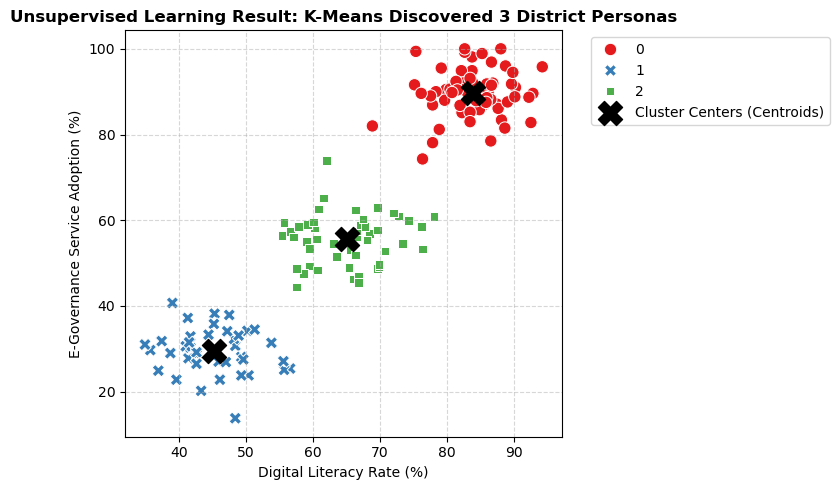

In [16]:
# Extract cluster centers (centroids)
centroids = kmeans.cluster_centers_

# 3. Plot the clustered results with Seaborn
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df_districts, 
    x='Digital_Literacy_Pct', 
    y='E_Governance_Usage_Pct', 
    hue='Cluster_ID', 
    palette='Set1', 
    s=80, 
    style='Cluster_ID'
)

# Plot the central 'brain' (centroids) of each cluster
plt.scatter(
    centroids[:, 0], centroids[:, 1], 
    s=300, c='black', marker='X', label='Cluster Centers (Centroids)'
)

plt.title("Unsupervised Learning Result: K-Means Discovered 3 District Personas", fontsize=12, fontweight='bold')
plt.xlabel("Digital Literacy Rate (%)")
plt.ylabel("E-Governance Service Adoption (%)")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()